In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df_cholesterol = pd.read_csv('./datasets/cholesterol_dataset.csv')

In [7]:
df_cholesterol.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Grupo Sanguíneo     996 non-null    str    
 1   Fumante             997 non-null    str    
 2   Nível de Atividade  996 non-null    str    
 3   Idade               997 non-null    float64
 4   Peso                997 non-null    float64
 5   Altura              997 non-null    float64
 6   Colesterol          1000 non-null   float64
dtypes: float64(4), str(3)
memory usage: 54.8 KB


In [6]:
df_cholesterol.drop(columns=['Id'], inplace=True)

/var/folders/j5/kt9ntjbn6zjf_xs_4f35ydgc0000gn/T/ipykernel_36709/215754173.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_cholesterol.drop(columns=['Id'], inplace=True)


In [8]:
df_cholesterol.columns= [
  'grupo_sanguineo',
  'fumante',
  'nivel_atividade_fisica',
  'idade',
  'peso',
  'altura',
  'nivel_colesterol'
]

In [9]:
df_cholesterol_eda = df_cholesterol.copy()

In [10]:
df_cholesterol_bucketing = df_cholesterol.copy()

# EDA

In [17]:
df_cholesterol_eda.head(10)

,grupo_sanguineo,fumante,nivel_atividade_fisica,idade,peso,altura,nivel_colesterol
0,B,Sim,Baixo,33.0,85.1,186.0,199.63
1,A,Não,Moderado,68.0,105.0,184.0,236.98
2,O,Não,Alto,25.0,64.8,180.0,161.79
3,A,Não,Alto,43.0,120.2,167.0,336.24
4,AB,Não,Baixo,79.0,88.5,175.0,226.23
5,B,Não,Baixo,68.0,66.8,170.0,185.31
6,A,Sim,Baixo,60.0,117.3,181.0,289.33
7,O,Sim,Moderado,35.0,86.9,174.0,216.48
8,O,Não,Baixo,62.0,81.3,166.0,235.30
9,B,Sim,Alto,44.0,32.7,165.0,97.79


In [18]:
df_cholesterol_eda.isna().sum()

grupo_sanguineo           4
fumante                   3
nivel_atividade_fisica    4
idade                     3
peso                      3
altura                    3
nivel_colesterol          0
dtype: int64

In [15]:
df_cholesterol_eda.describe()

,idade,peso,altura,nivel_colesterol
count,997.000000,997.000000,997.000000,1000.000000
mean,49.206620,76.496690,174.889669,199.453260
std,17.476704,21.439132,8.844703,50.625152
min,20.000000,15.400000,160.000000,36.260000
25%,34.000000,61.700000,167.000000,166.345000
50%,49.000000,75.500000,175.000000,199.455000
75%,65.000000,90.200000,183.000000,233.785000
max,79.000000,158.100000,190.000000,372.670000


In [19]:
blood_type_mode = df_cholesterol_eda.grupo_sanguineo.mode()
smoker_mode = df_cholesterol_eda.fumante.mode()
activity_level_mode = df_cholesterol_eda.nivel_atividade_fisica.mode()

In [22]:
age_median = df_cholesterol_eda.idade.median()
weight_median = df_cholesterol_eda.peso.median()
height_median = df_cholesterol_eda.altura.median()

In [23]:
df_cholesterol_eda.fillna(
  value={
    'grupo_sanguineo': blood_type_mode[0],
    'fumante': smoker_mode[0],
    'nivel_atividade_fisica': activity_level_mode[0],
    'idade': age_median,
    'peso': weight_median,
    'altura': height_median,
    },
  inplace=True
  )

,grupo_sanguineo,fumante,nivel_atividade_fisica,idade,peso,altura,nivel_colesterol
0,B,Sim,Baixo,33.0,85.1,186.0,199.63
1,A,Não,Moderado,68.0,105.0,184.0,236.98
2,O,Não,Alto,25.0,64.8,180.0,161.79
3,A,Não,Alto,43.0,120.2,167.0,336.24
4,AB,Não,Baixo,79.0,88.5,175.0,226.23
...,...,...,...,...,...,...,...
995,AB,Sim,Moderado,31.0,68.1,166.0,206.81
996,O,Não,Alto,51.0,47.7,170.0,128.03
997,AB,Não,Baixo,39.0,85.5,176.0,211.14
998,AB,Sim,Baixo,61.0,91.2,161.0,284.53


In [24]:
df_cholesterol_eda.isna().sum()

grupo_sanguineo           0
fumante                   0
nivel_atividade_fisica    0
idade                     0
peso                      0
altura                    0
nivel_colesterol          0
dtype: int64

In [25]:
df_cholesterol_eda.idade = df_cholesterol_eda.idade.astype(int)

In [26]:
df_cholesterol_eda.altura = df_cholesterol_eda.altura.astype(int)

In [27]:
df_cholesterol_eda.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   grupo_sanguineo         1000 non-null   str    
 1   fumante                 1000 non-null   str    
 2   nivel_atividade_fisica  1000 non-null   str    
 3   idade                   1000 non-null   int64  
 4   peso                    1000 non-null   float64
 5   altura                  1000 non-null   int64  
 6   nivel_colesterol        1000 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 54.8 KB


<Axes: xlabel='idade'>

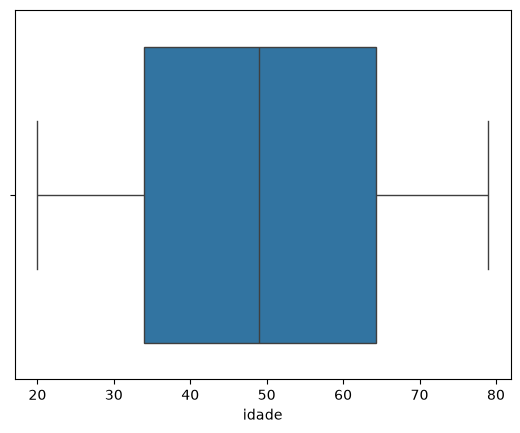

In [28]:
sns.boxplot(data=df_cholesterol_eda, x='idade')

<Axes: xlabel='peso'>

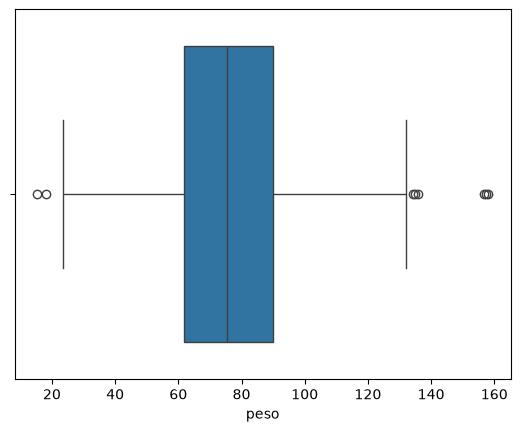

In [29]:
sns.boxplot(data=df_cholesterol_eda, x='peso')

In [30]:
# removing individuals whose weight is incompatible with the study for their age range
df_cholesterol_eda[df_cholesterol_eda['peso'] < 40].peso.count()

np.int64(37)

In [31]:
df_cholesterol_eda.drop(df_cholesterol_eda[df_cholesterol_eda['peso'] < 40].index, axis=0, inplace=True)

/var/folders/j5/kt9ntjbn6zjf_xs_4f35ydgc0000gn/T/ipykernel_36709/3107375239.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_cholesterol_eda.drop(df_cholesterol_eda[df_cholesterol_eda['peso'] < 40].index, axis=0, inplace=True)


<Axes: xlabel='peso'>

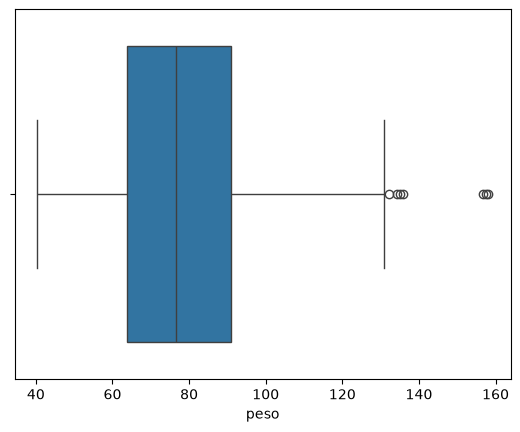

In [32]:
sns.boxplot(data=df_cholesterol_eda, x='peso')

<Axes: xlabel='altura'>

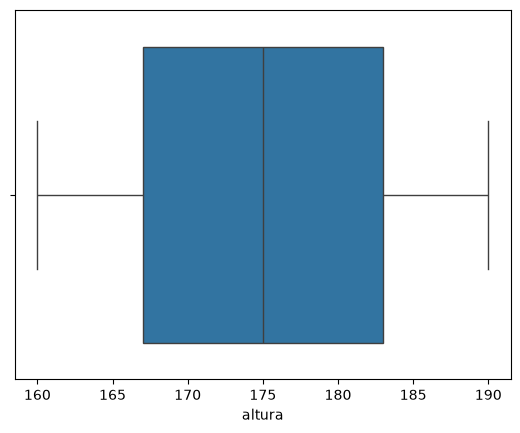

In [36]:
sns.boxplot(data=df_cholesterol_eda, x='altura')

<Axes: xlabel='nivel_colesterol'>

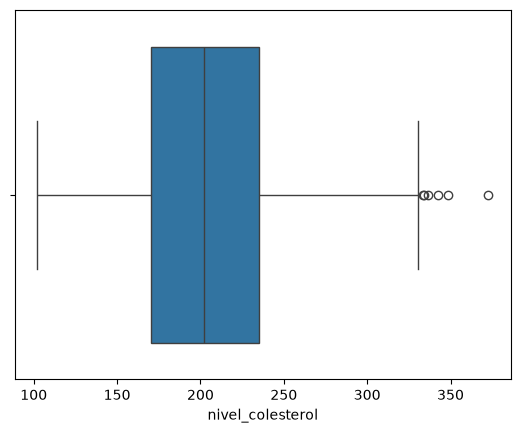

In [37]:
sns.boxplot(data=df_cholesterol_eda, x='nivel_colesterol')

<Axes: xlabel='grupo_sanguineo', ylabel='nivel_colesterol'>

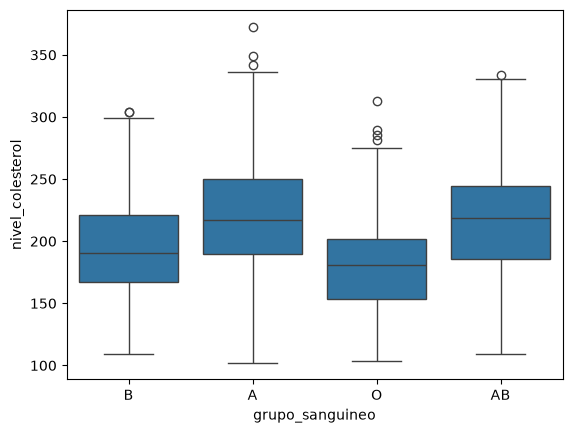

In [38]:
sns.boxplot(data=df_cholesterol_eda, x='grupo_sanguineo', y='nivel_colesterol')

<Axes: xlabel='fumante', ylabel='nivel_colesterol'>

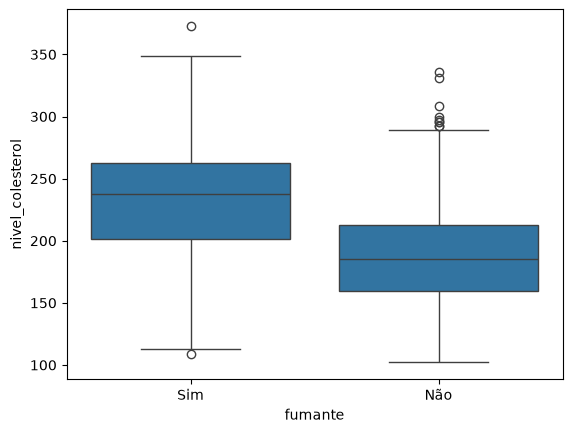

In [39]:
sns.boxplot(data=df_cholesterol_eda, x='fumante', y='nivel_colesterol')

<Axes: xlabel='nivel_atividade_fisica', ylabel='nivel_colesterol'>

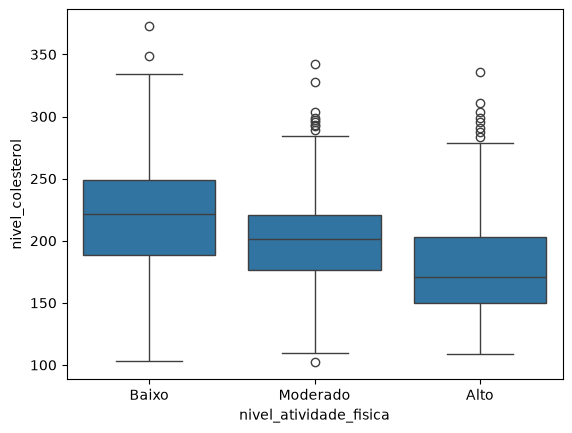

In [40]:
sns.boxplot(data=df_cholesterol_eda, x='nivel_atividade_fisica', y='nivel_colesterol')

<Axes: xlabel='idade', ylabel='nivel_colesterol'>

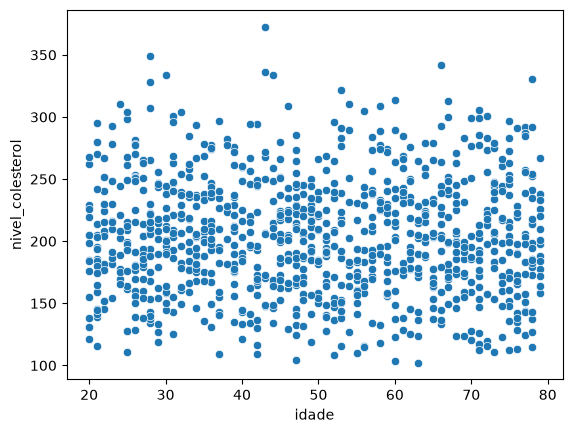

In [41]:
sns.scatterplot(data=df_cholesterol_eda, x='idade', y='nivel_colesterol')

<Axes: xlabel='peso', ylabel='nivel_colesterol'>

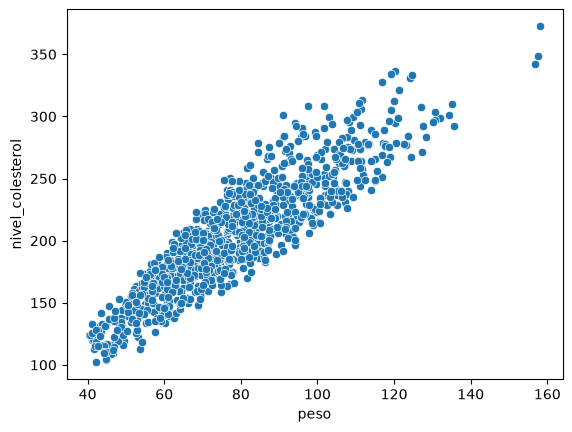

In [42]:
sns.scatterplot(data=df_cholesterol_eda, x='peso', y='nivel_colesterol')

<Axes: xlabel='altura', ylabel='nivel_colesterol'>

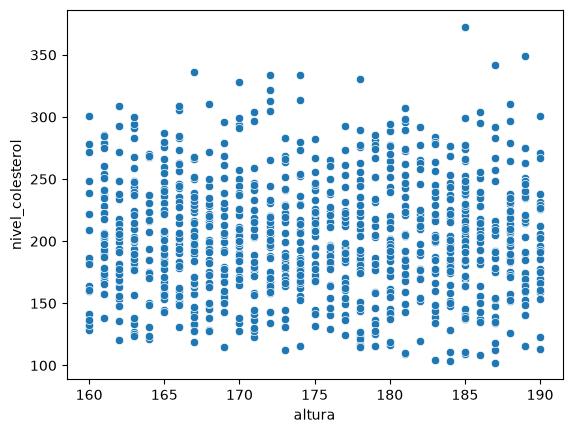

In [43]:
sns.scatterplot(data=df_cholesterol_eda, x='altura', y='nivel_colesterol')